# CSE498V2: Eye Disease Classification (DenseNet-only)

This notebook is set up to run **top-to-bottom**.

## What this version does
- Uses your dataset folder path (updated below).
- Builds a stratified train/val/test split.
- Trains **DenseNet121 (baseline)** and **DenseEyeNet (custom DenseNet-based CNN)**.
- Saves the trained model artifacts to your requested folder.
- Produces comparison graphs between the 2 models.

## What was removed (by request)
- ResNet, EfficientNet, MobileNetV3, ViT training sections
- Explainable AI (Grad-CAM++) section
- Federated Learning section (it depended on MobileNet)

In [17]:
"""CSE498V2: Eye Disease Classification (DenseNet-only)

This notebook is set up to run top-to-bottom.

What this version does
- Uses your dataset folder path (updated below).
- Builds a stratified train/val/test split.
- Trains DenseNet121 (baseline) and DenseEyeNet (custom DenseNet-based CNN).
- Saves the trained model artifacts to your requested folder.
- Produces comparison graphs between the 2 models.

What was removed (by request)
- ResNet, EfficientNet, MobileNetV3, ViT training sections
- Explainable AI (Grad-CAM++) section
- Federated Learning section
"""

# This cell is intentionally a no-op docstring.


'CSE498V2: Eye Disease Classification (DenseNet-only)\n\nThis notebook is set up to run top-to-bottom.\n\nWhat this version does\n- Uses your dataset folder path (updated below).\n- Builds a stratified train/val/test split.\n- Trains DenseNet121 (baseline) and DenseEyeNet (custom DenseNet-based CNN).\n- Saves the trained model artifacts to your requested folder.\n- Produces comparison graphs between the 2 models.\n\nWhat was removed (by request)\n- ResNet, EfficientNet, MobileNetV3, ViT training sections\n- Explainable AI (Grad-CAM++) section\n- Federated Learning section\n'

In [18]:
# 1) Optional: install missing packages (safe to re-run)
# Note: Explainable AI packages were removed by request.
import importlib
import subprocess
import sys


def ensure_package(import_name: str, pip_name: str | None = None):
    try:
        importlib.import_module(import_name)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or import_name])


# (Optional) Only needed if you later add back ViT or other timm models
# ensure_package("timm")


In [19]:
# 2) Imports and global config
import os
import copy
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision
from torchvision import transforms
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report


In [20]:
# 3) Paths and runtime setup
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Dataset (updated as requested)
DATASET_DIR = Path(r"D:\NSU Course\2026\CSE498R\Eye Disease Image Dataset\Eye Disease Image Dataset\Augmented Dataset\Augmented Dataset")

# Model output folder (updated as requested)
MODEL_DIR = Path(r"D:\CSE498 Research Updated\CSE498R models\Custom CNN models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Dataset:", DATASET_DIR)
print("Model output:", MODEL_DIR)


Device: cuda
Dataset: D:\NSU Course\2026\CSE498R\Eye Disease Image Dataset\Eye Disease Image Dataset\Augmented Dataset\Augmented Dataset
Model output: D:\CSE498 Research Updated\CSE498R models\Custom CNN models


In [21]:
# 3b) Device check: which backend PyTorch will use for training
import torch

cuda_ok = torch.cuda.is_available()
print("torch.cuda.is_available():", cuda_ok)
if cuda_ok:
    print("Using: GPU (CUDA)")
    print("  device count:", torch.cuda.device_count())
    print("  current device:", torch.cuda.current_device())
    print("  name:", torch.cuda.get_device_name(0))
else:
    print("Using: CPU (no CUDA device visible to PyTorch)")

print("torch.version.cuda (build):", torch.version.cuda)
print("Recommended training device for this notebook:", "cuda" if cuda_ok else "cpu")


torch.cuda.is_available(): True
Using: GPU (CUDA)
  device count: 1
  current device: 0
  name: NVIDIA GeForce GTX 1650
torch.version.cuda (build): 11.8
Recommended training device for this notebook: cuda


In [22]:
# 4) Build image index
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

class_dirs = [d for d in sorted(DATASET_DIR.iterdir()) if d.is_dir()]
if not class_dirs:
    raise RuntimeError(f"No class folders found in: {DATASET_DIR}")

class_names = [d.name for d in class_dirs]
class_to_idx = {c: i for i, c in enumerate(class_names)}

rows = []
for class_dir in class_dirs:
    label_name = class_dir.name
    label_idx = class_to_idx[label_name]
    for p in class_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in VALID_EXTS:
            rows.append((str(p), label_idx, label_name))

df = pd.DataFrame(rows, columns=["path", "label", "class_name"])
if df.empty:
    raise RuntimeError("No images found in dataset.")

print("Total images:", len(df))
print("Total classes:", len(class_names))
display(df["class_name"].value_counts().sort_index())


Total images: 16242
Total classes: 10


class_name
Central Serous Chorioretinopathy [Color Fundus]     606
Diabetic Retinopathy                               3444
Disc Edema                                          762
Glaucoma                                           2880
Healthy                                            2676
Macular Scar                                       1937
Myopia                                             2251
Pterygium                                           102
Retinal Detachment                                  750
Retinitis Pigmentosa                                834
Name: count, dtype: int64

## Dataset preview (sanity check)

Below is **one random image per class** from the full image index (before splitting). This helps confirm:
- The folder-to-label mapping looks correct
- Images load properly
- Classes visually match the intended disease categories


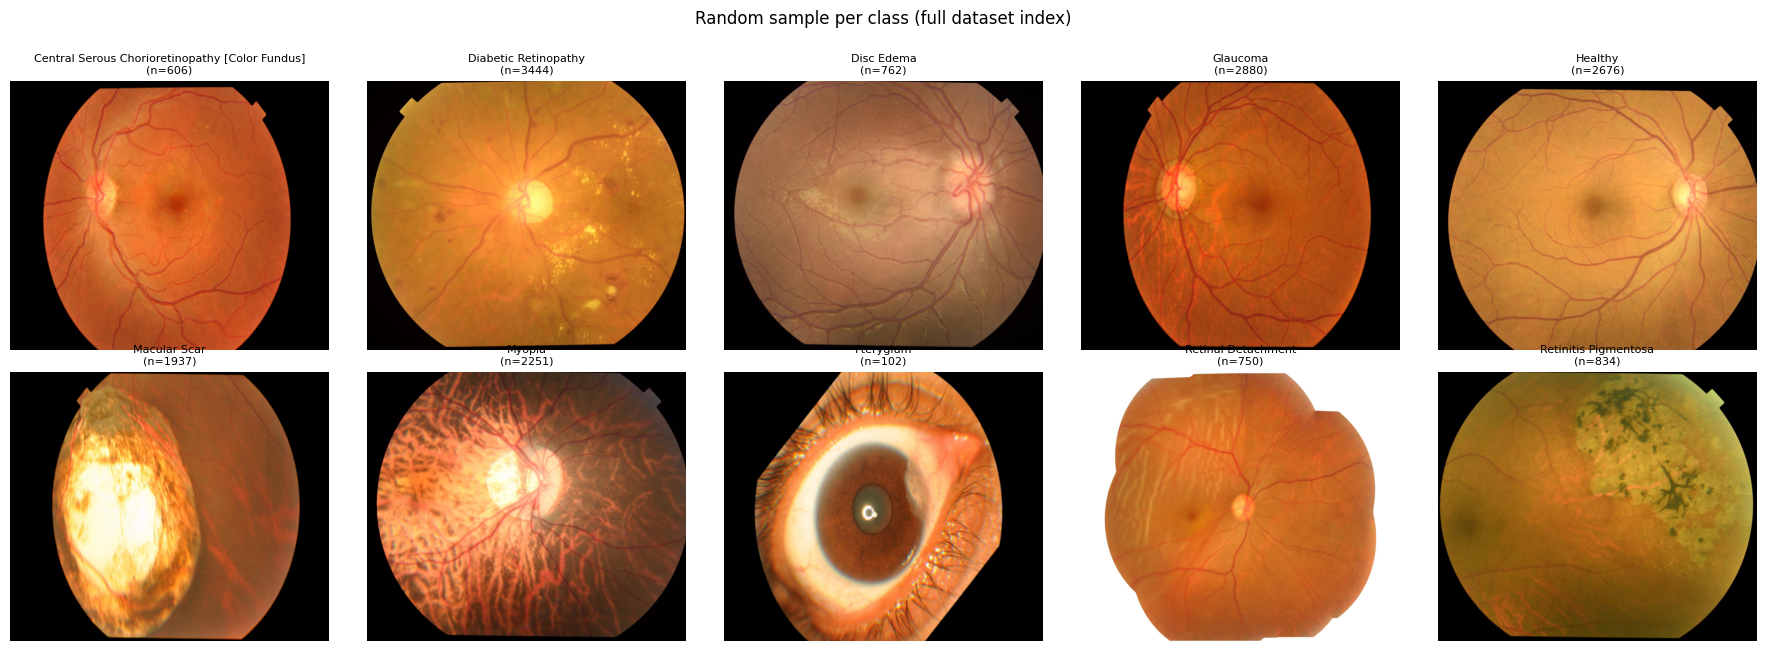

In [23]:
# 4b) Visualize dataset images: one sample per class (all types)
import math

rng = np.random.default_rng(SEED)
n_classes = len(class_names)
cols = min(5, n_classes)
rows = math.ceil(n_classes / cols)

fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.2 * rows))
axes = np.atleast_1d(axes).ravel()

for i, cname in enumerate(class_names):
    ax = axes[i]
    subset = df[df["class_name"] == cname]
    if subset.empty:
        ax.text(0.5, 0.5, "no images", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(cname, fontsize=8)
        ax.axis("off")
        continue
    pick = int(rng.integers(0, len(subset)))
    path = subset.iloc[pick]["path"]
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{cname}\n(n={len(subset)})", fontsize=8)
    ax.axis("off")

for j in range(n_classes, len(axes)):
    axes[j].axis("off")

plt.suptitle("Random sample per class (full dataset index)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


In [24]:
# 5) Stratified train/val/test split (70/15/15)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"],
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"],
)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))


Train: 11369 Val: 2436 Test: 2437


C:\Users\mdsha\AppData\Local\Temp\ipykernel_6956\1402975723.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
C:\Users\mdsha\AppData\Local\Temp\ipykernel_6956\1402975723.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
C:\Users\mdsha\AppData\Local\Temp\ipykernel_6956\1402975723.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


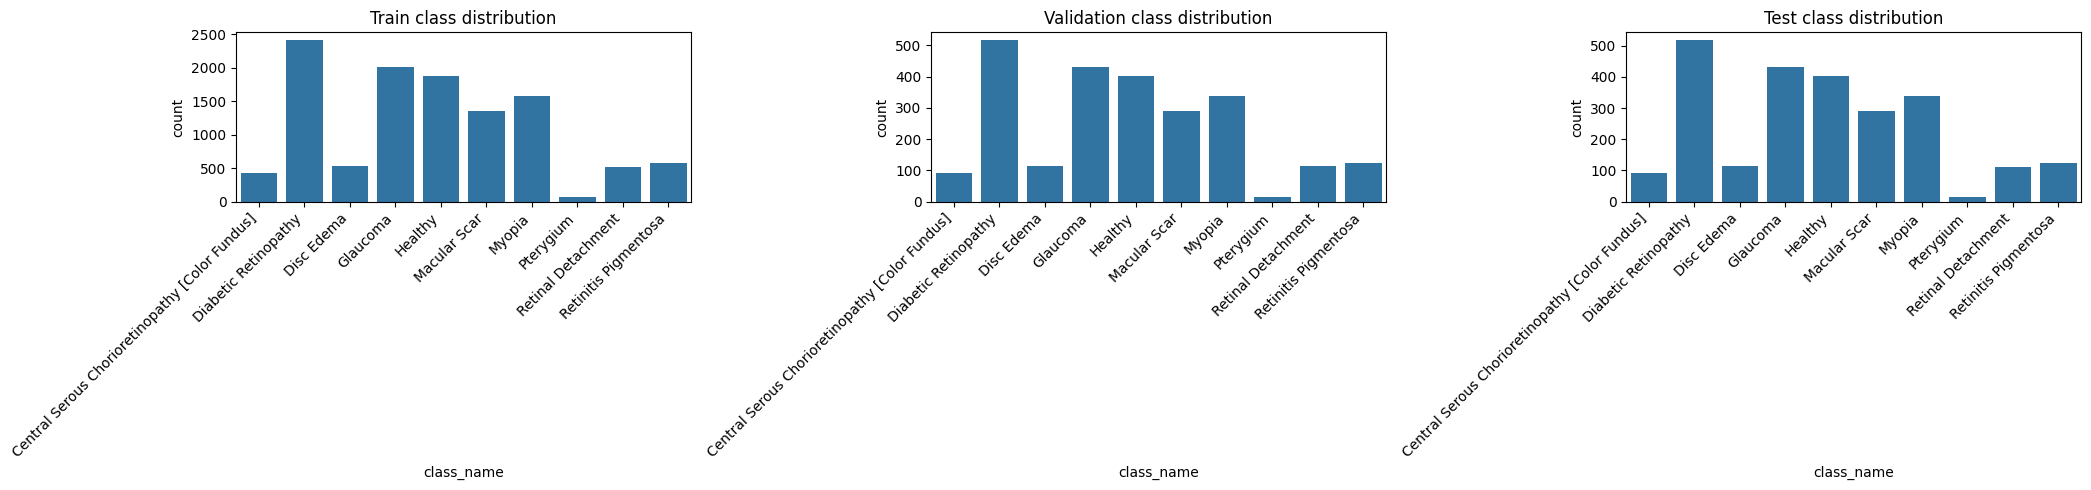

In [25]:
# 6) Visualize split distribution
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, data, title in zip(
    axes,
    [train_df, val_df, test_df],
    ["Train", "Validation", "Test"],
):
    vc = data["class_name"].value_counts().sort_index()
    sns.barplot(x=vc.index, y=vc.values, ax=ax)
    ax.set_title(f"{title} class distribution")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()


In [26]:
# 7) Dataset + transforms
IMG_SIZE = 224
INCEPTION_SIZE = 299
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
NUM_WORKERS = 0  # stable in Windows notebooks
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


class EyeDiseaseDataset(Dataset):
    def __init__(self, data_df: pd.DataFrame, transform=None):
        self.data_df = data_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data_df)

    def __getitem__(self, idx):
        row = self.data_df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        label = int(row["label"])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

inception_train_tfms = transforms.Compose([
    transforms.Resize((INCEPTION_SIZE, INCEPTION_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

inception_eval_tfms = transforms.Compose([
    transforms.Resize((INCEPTION_SIZE, INCEPTION_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


In [27]:
# 8) DataLoaders with class balancing
train_dataset = EyeDiseaseDataset(train_df, transform=train_tfms)
val_dataset = EyeDiseaseDataset(val_df, transform=eval_tfms)
test_dataset = EyeDiseaseDataset(test_df, transform=eval_tfms)

inception_train_dataset = EyeDiseaseDataset(train_df, transform=inception_train_tfms)
inception_val_dataset = EyeDiseaseDataset(val_df, transform=inception_eval_tfms)
inception_test_dataset = EyeDiseaseDataset(test_df, transform=inception_eval_tfms)

label_counts = Counter(train_df["label"].tolist())
sample_weights = [1.0 / label_counts[int(lbl)] for lbl in train_df["label"].tolist()]
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

inception_train_loader = DataLoader(inception_train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
inception_val_loader = DataLoader(inception_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
inception_test_loader = DataLoader(inception_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("Data loaders are ready.")


Data loaders are ready.


In [28]:
# 9) Model setup (DenseNet-only)
# This notebook intentionally keeps only DenseNet-based models.
NUM_CLASSES = len(class_names)


def create_densenet121(num_classes: int):
    """Optional baseline (not trained by default in this notebook)."""
    model = torchvision.models.densenet121(weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model


In [29]:
# 10) Training / evaluation helpers
from tqdm.auto import tqdm

EPOCHS = 10 if torch.cuda.is_available() else 4
SHOW_TRAIN_PROGRESS = True  # tqdm batch bar during each epoch; set False for epoch-end logs only
PROGRESS_LOG_INTERVAL = 50  # when SHOW_TRAIN_PROGRESS is False, print every N batches (heartbeat)
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4

class_weights_np = []
for i in range(NUM_CLASSES):
    class_weights_np.append(len(train_df) / (NUM_CLASSES * max(label_counts[i], 1)))
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)


def unwrap_logits(outputs):
    if isinstance(outputs, torch.Tensor):
        return outputs
    if hasattr(outputs, "logits"):
        return outputs.logits
    if isinstance(outputs, (tuple, list)):
        return outputs[0]
    return outputs


def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    running_loss = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = unwrap_logits(model(x))
            loss = criterion(out, y)
            preds = out.argmax(dim=1)
            running_loss += loss.item() * x.size(0)
            y_true.extend(y.cpu().numpy().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())

    loss = running_loss / max(len(loader.dataset), 1)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "loss": loss,
        "accuracy": acc,
        "precision": p,
        "recall": r,
        "f1": f1,
        "y_true": y_true,
        "y_pred": y_pred,
    }


def train_one_model(model_name, model, train_dl, val_dl, image_size, epochs=EPOCHS):
    print(f"\n===== Training {model_name} =====")
    model = model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_f1 = -1.0
    best_state = None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())
    start = time.time()

    n_batches = len(train_dl)
    total_steps = max(epochs * n_batches, 1)
    overall = None
    if SHOW_TRAIN_PROGRESS:
        overall = tqdm(total=total_steps, desc=f"{model_name} | overall", leave=True, dynamic_ncols=True, mininterval=0.5)

    for epoch in range(epochs):
        model.train()
        run_loss = 0.0
        run_correct = 0
        run_count = 0

        print(
            f"[{model_name}] Epoch {epoch + 1}/{epochs} — {n_batches} batches (started {time.strftime('%H:%M:%S')})",
            flush=True,
        )

        for step, (x, y) in enumerate(train_dl, start=1):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                out = unwrap_logits(model(x))
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            preds = out.argmax(dim=1)
            run_loss += loss.item() * x.size(0)
            run_correct += (preds == y).sum().item()
            run_count += x.size(0)

            if overall is not None:
                overall.update(1)
                if step % 10 == 0 or step == n_batches:
                    overall.set_postfix({"epoch": f"{epoch+1}/{epochs}", "loss": f"{loss.item():.4f}"})

            if (not SHOW_TRAIN_PROGRESS) and (step % PROGRESS_LOG_INTERVAL == 0 or step == n_batches):
                print(
                    f"  ... batch {step}/{n_batches} loss={loss.item():.4f} ({time.strftime('%H:%M:%S')})",
                    flush=True,
                )

        scheduler.step()

        train_loss = run_loss / max(run_count, 1)
        train_acc = run_correct / max(run_count, 1)
        val_metrics = evaluate_model(model, val_dl)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_metrics["f1"])

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} val_f1={val_metrics['f1']:.4f}"
        )

        if val_metrics["f1"] > best_f1:
            best_f1 = val_metrics["f1"]
            best_state = copy.deepcopy(model.state_dict())

    if overall is not None:
        overall.close()

    elapsed = time.time() - start
    model.load_state_dict(best_state)

    save_name = model_name.lower().replace(" ", "_").replace("-", "_")
    weights_path = MODEL_DIR / f"{save_name}_best.pth"
    bundle_path = MODEL_DIR / f"{save_name}_bundle.pth"
    torch.save(model.state_dict(), weights_path)
    torch.save(
        {
            "architecture": model_name,
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "image_size": image_size,
            "mean": MEAN,
            "std": STD,
        },
        bundle_path,
    )
    print("Saved:", weights_path)
    print("Saved bundle:", bundle_path)

    return model.cpu(), history, elapsed, str(weights_path), str(bundle_path)


def train_models_entries(model_specs):
    """Train a list of (name, model, train_dl, val_dl, test_dl, input_size) specs; merges into globals."""
    g = globals()
    if "all_results" not in g:
        g["all_results"] = []
    if "all_histories" not in g:
        g["all_histories"] = {}
    if "all_confusions" not in g:
        g["all_confusions"] = {}
    if "best_models" not in g:
        g["best_models"] = {}

    for model_name, model, tr_dl, va_dl, te_dl, input_size in model_specs:
        try:
            best_model, hist, train_time, w_path, b_path = train_one_model(
                model_name=model_name,
                model=model,
                train_dl=tr_dl,
                val_dl=va_dl,
                image_size=input_size,
                epochs=EPOCHS,
            )
            test_metrics = evaluate_model(best_model.to(device), te_dl)
            g["all_results"].append(
                {
                    "Model": model_name,
                    "Accuracy": test_metrics["accuracy"],
                    "Precision": test_metrics["precision"],
                    "Recall": test_metrics["recall"],
                    "F1": test_metrics["f1"],
                    "Training Time (s)": train_time,
                    "Weights Path": w_path,
                    "Bundle Path": b_path,
                }
            )
            g["all_histories"][model_name] = hist
            g["all_confusions"][model_name] = (test_metrics["y_true"], test_metrics["y_pred"])
            g["best_models"][model_name] = best_model.cpu()
            torch.cuda.empty_cache()
        except RuntimeError as ex:
            print(f"Model failed: {model_name} -> {ex}")
            print("Skipping and continuing so notebook does not stop.")
            torch.cuda.empty_cache()


In [30]:
# 11) Training (DenseNet-only)
# Non-DenseNet models removed by request.
# Train the DenseNet-based model below (DenseEyeNet, later in this notebook).


In [31]:
# (Removed) EfficientNet training cell


In [32]:
# 11a) Train DenseNet121 (baseline DenseNet)
# Baseline to compare against the custom DenseEyeNet below.
train_models_entries(
    [
        ("DenseNet121", create_densenet121(NUM_CLASSES), train_loader, val_loader, test_loader, IMG_SIZE),
    ]
)



===== Training DenseNet121 =====



DenseNet121 | overall:   0%|                                                                  | 0/3560 [00:00<?, ?it/s]

[DenseNet121] Epoch 1/10 — 356 batches (started 02:57:42)



DenseNet121 | overall:   0%|                                                        | 1/3560 [00:04<4:09:16,  4.20s/it]
DenseNet121 | overall:   0%|                                                        | 2/3560 [00:08<4:00:33,  4.06s/it]
DenseNet121 | overall:   0%|                                                        | 3/3560 [00:12<3:57:23,  4.00s/it]
DenseNet121 | overall:   0%|                                                        | 4/3560 [00:16<3:55:52,  3.98s/it]
DenseNet121 | overall:   0%|                                                        | 5/3560 [00:20<3:55:23,  3.97s/it]
DenseNet121 | overall:   0%|                                                        | 6/3560 [00:24<3:55:49,  3.98s/it]
DenseNet121 | overall:   0%|                                                        | 7/3560 [00:28<3:57:22,  4.01s/it]
DenseNet121 | overall:   0%|▏                                                       | 8/3560 [00:32<3:56:12,  3.99s/it]
DenseNet121 | overall:   0%|▏          

Epoch 1/10 | train_loss=0.2824 train_acc=0.7320 | val_loss=0.5283 val_acc=0.7360 val_f1=0.7006
[DenseNet121] Epoch 2/10 — 356 batches (started 03:22:42)


...

Epoch 10/10 | train_loss=0.0304 train_acc=0.9576 | val_loss=0.1748 val_acc=0.9146 val_f1=0.9145


Saved: D:\CSE498 Research Updated\CSE498R models\Custom CNN models\densenet121_best.pth
Saved bundle: D:\CSE498 Research Updated\CSE498R models\Custom CNN models\densenet121_bundle.pth


[DenseNet121] Epoch 1/10 — 356 batches (started 02:49:41)


DenseNet121 | overall:   1%|▎                             | 37/3560 [02:35<4:05:56,  4.19s/it, epoch=1/10, loss=0.3309]

KeyboardInterrupt: 

In [33]:
# (Removed) MobileNetV3 training cell


In [34]:
# (Removed) ViT training cell

In [35]:
# 12) Results table
results_df = pd.DataFrame(all_results).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df)

if results_df.empty:
    raise RuntimeError("No model completed training. Reduce model count or epochs, then run again.")


,Model,Accuracy,Precision,Recall,F1,Training Time (s),Weights Path,Bundle Path
0,DenseNet121,0.901929,0.902896,0.901929,0.901532,14639.402204,D:\CSE498 Research Updated\CSE498R models\Cust...,D:\CSE498 Research Updated\CSE498R models\Cust...


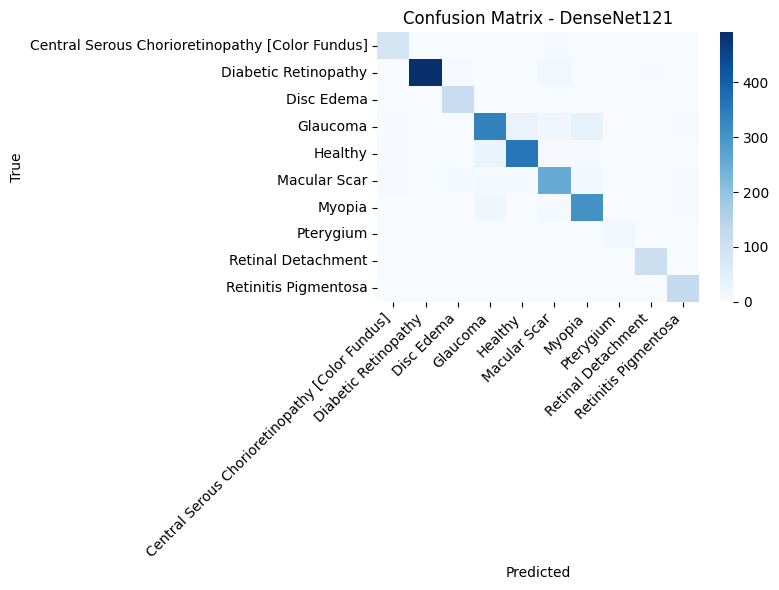

In [36]:
# 13) Plot confusion matrices for trained models
def plot_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


for m_name, (y_true, y_pred) in all_confusions.items():
    plot_confusion_matrix(y_true, y_pred, class_names, f"Confusion Matrix - {m_name}")


In [37]:
# 14) Single-image prediction helper
def preprocess_pil(pil_img, image_size=224):
    tfm = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return tfm(pil_img.convert("RGB")).unsqueeze(0)


def predict_single(model, pil_img, image_size=224):
    model = model.to(device).eval()
    x = preprocess_pil(pil_img, image_size=image_size).to(device)
    with torch.no_grad():
        out = unwrap_logits(model(x))
        probs = torch.softmax(out, dim=1)[0]
        pred_idx = int(torch.argmax(probs).item())
    return class_names[pred_idx], float(probs[pred_idx].item()), probs.cpu().numpy()


Best model: DenseNet121


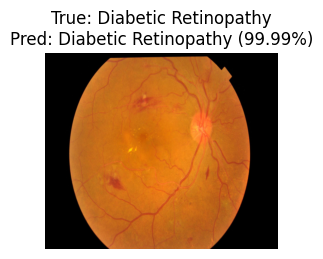

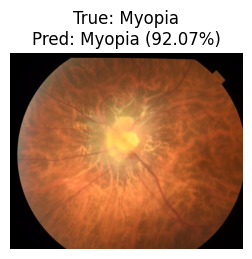

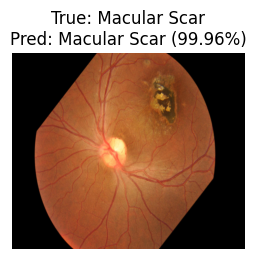

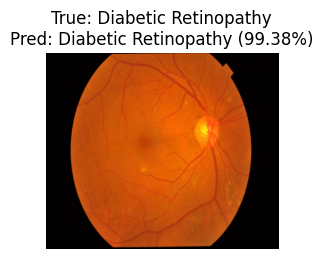

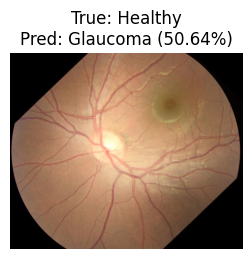

In [38]:
# 15) Quick qualitative check
best_row = results_df.iloc[0]
best_model_name = best_row["Model"]
best_model = best_models[best_model_name]
best_size = 224
print("Best model:", best_model_name)

sample_paths = test_df.sample(n=min(5, len(test_df)), random_state=SEED)["path"].tolist()
for p in sample_paths:
    img = Image.open(p).convert("RGB")
    pred_name, conf, _ = predict_single(best_model, img, image_size=best_size)
    true_name = Path(p).parent.name
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"True: {true_name}\nPred: {pred_name} ({conf:.2%})")
    plt.show()


In [39]:
# (Removed) Explainable AI (Grad-CAM++) setup
# This section was removed by request.


In [40]:
# (Removed) Explainable AI (Grad-CAM++) run cell
# This section was removed by request.


In [41]:
# (Removed) Federated Learning setup
# This section was removed because it depended on MobileNetV3 and you requested DenseNet-only.


In [42]:
# (Removed) Federated helper functions


In [43]:
# (Removed) Federated learning run cell


In [44]:
# 18) Saved artifact summary
print("=== Saved model files ===")
for p in sorted(MODEL_DIR.glob("*")):
    print(p.name)

artifact_df = pd.DataFrame(
    {
        "Artifact": [p.name for p in sorted(MODEL_DIR.glob("*"))],
        "Path": [str(p) for p in sorted(MODEL_DIR.glob("*"))],
    }
)
display(artifact_df)


=== Saved model files ===
densenet121_best.pth
densenet121_bundle.pth


,Artifact,Path
0,densenet121_best.pth,D:\CSE498 Research Updated\CSE498R models\Cust...
1,densenet121_bundle.pth,D:\CSE498 Research Updated\CSE498R models\Cust...


## Common runtime issues and quick fixes

- **Dataset path errors**: verify `DATASET_DIR` points to the folder that contains the **10 class subfolders**.
- **Training is slow** (especially on CPU): reduce `_FAST_SIZE` (e.g., 128) and/or `_FAST_BATCH` (e.g., 16) in the DenseEyeNet Phase 1/2 cells.
- **Training looks stuck**: keep `SHOW_TRAIN_PROGRESS = True` to see the tqdm progress bars.
- **Very poor metrics**: confirm class folders are correct, and consider increasing Phase 2 epochs.


In [46]:
## DenseEyeNet (DenseNet-based custom CNN)

This section defines the **DenseEyeNet** architecture (built on a DenseNet121 backbone) and prepares it for training.

- Multi-scale DenseNet feature fusion
- SE attention on fused features
- Regularized classification head

SyntaxError: invalid syntax (1299295291.py, line 3)

In [47]:
# ══════════════════════════════════════════════════════════════════
# DenseEyeNet — Custom CNN built on DenseNet121 backbone
#
# Novelty over standard DenseNet121:
#   1. Multi-scale feature extraction from 3 internal DenseNet
#      stages instead of just the final layer
#   2. Squeeze-and-Excitation (SE) channel attention on fused
#      features
#   3. Deep regularized classification head with BatchNorm +
#      Dropout replacing the single Linear classifier
#   4. Two-phase training: frozen backbone first, then full
#      fine-tune end-to-end
# ══════════════════════════════════════════════════════════════════

import torch.nn.functional as F


class SEBlock1D(nn.Module):
    """
    1D Squeeze-and-Excitation block for feature vectors.
    Learns which feature channels matter most per disease class.
    """
    def __init__(self, channels, reduction=16):
        super().__init__()
        mid = max(channels // reduction, 8)
        self.fc = nn.Sequential(
            nn.Linear(channels, mid),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels),
            nn.Sigmoid(),
        )

    def forward(self, x):
        # x: (B, channels) — element-wise channel reweighting
        return x * self.fc(x)


class DenseEyeNet(nn.Module):
    """
    DenseEyeNet: DenseNet121 backbone + custom multi-scale head.

    Stage A: stem + denseblock1 + transition1  →  128-d vector
    Stage B: denseblock2 + transition2          →  256-d vector
    Stage C: denseblock3 + transition3
             + denseblock4 + norm5              → 1024-d vector

    Fusion : concat → (B, 1408)
             Linear projection → (B, 512) + BN + ReLU
             SE channel attention → (B, 512)

    Head   : Dropout(0.4)
             Linear(512, 256) + BN + ReLU
             Dropout(0.3)
             Linear(256, 128) + BN + ReLU
             Dropout(0.2)
             Linear(128, num_classes)
    """

    def __init__(self, num_classes=10, dropout=0.4):
        super().__init__()

        # Load DenseNet121 with ImageNet pre-trained weights
        base  = torchvision.models.densenet121(
            weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1
        )
        feats = base.features

        # ── Split backbone into 3 stages ─────────────────────────
        self.stage_a = nn.Sequential(
            feats.conv0,
            feats.norm0,
            feats.relu0,
            feats.pool0,
            feats.denseblock1,
            feats.transition1,
        )  # output: (B, 128, 28, 28) for 224x224 input

        self.stage_b = nn.Sequential(
            feats.denseblock2,
            feats.transition2,
        )  # output: (B, 256, 14, 14)

        self.stage_c = nn.Sequential(
            feats.denseblock3,
            feats.transition3,
            feats.denseblock4,
            feats.norm5,
        )  # output: (B, 1024, 7, 7)

        # ── Global average pooling for each stage ─────────────────
        self.gap_a = nn.AdaptiveAvgPool2d(1)   # → (B, 128)
        self.gap_b = nn.AdaptiveAvgPool2d(1)   # → (B, 256)
        self.gap_c = nn.AdaptiveAvgPool2d(1)   # → (B, 1024)

        # Fused size: 128 + 256 + 1024 = 1408
        fused_dim = 1408

        # ── Fusion projection ─────────────────────────────────────
        self.fuse_proj = nn.Sequential(
            nn.Linear(fused_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
        )

        # ── SE attention on 512-d fused vector ───────────────────
        self.se = SEBlock1D(512, reduction=16)

        # ── Deep classification head ──────────────────────────────
        self.head = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout * 0.75),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout * 0.5),
            nn.Linear(128, num_classes),
        )

        # Initialize only custom layers, not pre-trained backbone
        self._init_custom_weights()

    def _init_custom_weights(self):
        for module in [self.fuse_proj, self.se, self.head]:
            for m in module.modules():
                if isinstance(m, nn.Linear):
                    nn.init.xavier_normal_(m.weight)
                    if m.bias is not None:
                        nn.init.zeros_(m.bias)
                elif isinstance(m, nn.BatchNorm1d):
                    nn.init.constant_(m.weight, 1)
                    nn.init.constant_(m.bias, 0)

    def forward(self, x):
        # Multi-scale feature extraction
        a = self.stage_a(x)                      # (B, 128, 28, 28)
        b = self.stage_b(a)                      # (B, 256, 14, 14)
        c = self.stage_c(b)                      # (B, 1024,  7,  7)

        # Global pooling → vectors
        va = self.gap_a(a).flatten(1)            # (B, 128)
        vb = self.gap_b(b).flatten(1)            # (B, 256)
        vc = self.gap_c(F.relu(c)).flatten(1)    # (B, 1024)

        # Concatenate all scales
        fused = torch.cat([va, vb, vc], dim=1)  # (B, 1408)

        # Project + SE attention
        proj = self.fuse_proj(fused)             # (B, 512)
        proj = self.se(proj)                     # (B, 512)

        # Classify
        return self.head(proj)                   # (B, num_classes)


def create_dense_eye_net(num_classes: int):
    return DenseEyeNet(num_classes=num_classes, dropout=0.4)


# ── Sanity check ──────────────────────────────────────────────────
_m  = create_dense_eye_net(NUM_CLASSES)
_x  = torch.randn(2, 3, 224, 224)
_o  = _m(_x)
_tp = sum(p.numel() for p in _m.parameters())
_tr = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"DenseEyeNet output shape : {_o.shape}")
print(f"Total parameters         : {_tp:,}")
print(f"Trainable parameters     : {_tr:,}")
del _m, _x, _o
print("DenseEyeNet architecture ready.")

DenseEyeNet output shape : torch.Size([2, 10])
Total parameters         : 7,875,882
Trainable parameters     : 7,875,882
DenseEyeNet architecture ready.


In [48]:
## Training — Phase 1 (freeze backbone)

Train only the **custom head** while keeping the DenseNet backbone frozen. This stabilizes training and quickly adapts the classifier to the dataset.

SyntaxError: invalid syntax (2515596756.py, line 3)

In [49]:
# ── DenseEyeNet Phase 1: head only, backbone frozen ───────────────
# Optimizations applied:
#   1. EPOCHS = 3 instead of 5
#   2. BATCH_SIZE = 32
#   3. Image size reduced to 160x160
#   4. Backbone fully frozen (only head trains)
# ──────────────────────────────────────────────────────────────────

print("=" * 60)
print("DenseEyeNet PHASE 1 — Frozen backbone, training head only")
print("=" * 60)

# ── Fast dataloaders at 160x160 ───────────────────────────────────
_FAST_SIZE  = 160
_FAST_BATCH = 32

_fast_train_tfms = transforms.Compose([
    transforms.Resize((_FAST_SIZE, _FAST_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15,
                           saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
_fast_eval_tfms = transforms.Compose([
    transforms.Resize((_FAST_SIZE, _FAST_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

_fast_train_loader = DataLoader(
    EyeDiseaseDataset(train_df, transform=_fast_train_tfms),
    batch_size=_FAST_BATCH,
    sampler=sampler,
    num_workers=0,
)
_fast_val_loader = DataLoader(
    EyeDiseaseDataset(val_df, transform=_fast_eval_tfms),
    batch_size=_FAST_BATCH,
    shuffle=False,
    num_workers=0,
)
_fast_test_loader = DataLoader(
    EyeDiseaseDataset(test_df, transform=_fast_eval_tfms),
    batch_size=_FAST_BATCH,
    shuffle=False,
    num_workers=0,
)
print(f"Fast loaders ready — image size: {_FAST_SIZE}x{_FAST_SIZE}  "
      f"batch: {_FAST_BATCH}")

# ── Build model ───────────────────────────────────────────────────
_dense_eye_p1 = create_dense_eye_net(NUM_CLASSES)

# Freeze all backbone stages
for p in _dense_eye_p1.stage_a.parameters():
    p.requires_grad = False
for p in _dense_eye_p1.stage_b.parameters():
    p.requires_grad = False
for p in _dense_eye_p1.stage_c.parameters():
    p.requires_grad = False

_tr_p1 = sum(p.numel() for p in _dense_eye_p1.parameters()
             if p.requires_grad)
print(f"Trainable params Phase 1 : {_tr_p1:,}")
print(f"Device                   : {device}")

# ── Quick forward pass check ──────────────────────────────────────
_dense_eye_p1 = _dense_eye_p1.to(device)
_test_x = torch.randn(2, 3, _FAST_SIZE, _FAST_SIZE).to(device)
with torch.no_grad():
    _test_out = _dense_eye_p1(_test_x)
print(f"Forward pass check       : {_test_out.shape} ✅")
del _test_x, _test_out
_dense_eye_p1 = _dense_eye_p1.cpu()

# ── Initialize global containers if not present ───────────────────
if "all_results"   not in globals(): all_results   = []
if "all_histories" not in globals(): all_histories = {}
if "all_confusions"not in globals(): all_confusions= {}
if "best_models"   not in globals(): best_models   = {}

# ── Save and override globals ─────────────────────────────────────
_orig_epochs = EPOCHS
_orig_lr     = LEARNING_RATE
EPOCHS        = 3
LEARNING_RATE = 1e-3

print(f"\nStarting Phase 1 — {EPOCHS} epochs at {_FAST_SIZE}x{_FAST_SIZE}...")

try:
    best_model_p1, hist_p1, time_p1, w_p1, b_p1 = train_one_model(
        model_name="DenseEyeNet",
        model=_dense_eye_p1,
        train_dl=_fast_train_loader,
        val_dl=_fast_val_loader,
        image_size=_FAST_SIZE,
        epochs=EPOCHS,
    )

    # Evaluate on test set
    test_metrics_p1 = evaluate_model(
        best_model_p1.to(device), _fast_test_loader
    )

    # Save into global containers
    all_results.append({
        "Model":             "DenseEyeNet",
        "Accuracy":          test_metrics_p1["accuracy"],
        "Precision":         test_metrics_p1["precision"],
        "Recall":            test_metrics_p1["recall"],
        "F1":                test_metrics_p1["f1"],
        "Training Time (s)": time_p1,
        "Weights Path":      w_p1,
        "Bundle Path":       b_p1,
    })
    all_histories["DenseEyeNet"]  = hist_p1
    all_confusions["DenseEyeNet"] = (test_metrics_p1["y_true"],
                                     test_metrics_p1["y_pred"])
    best_models["DenseEyeNet"]    = best_model_p1.cpu()

    torch.cuda.empty_cache()
    print(f"\nPhase 1 complete ✅")
    print(f"  Accuracy : {test_metrics_p1['accuracy']:.4f}")
    print(f"  F1       : {test_metrics_p1['f1']:.4f}")
    print(f"  best_models['DenseEyeNet'] saved ✅")

except Exception as ex:
    print(f"\n❌ Phase 1 failed: {ex}")
    raise

# ── Restore globals ───────────────────────────────────────────────
EPOCHS        = _orig_epochs
LEARNING_RATE = _orig_lr

DenseEyeNet PHASE 1 — Frozen backbone, training head only
Fast loaders ready — image size: 160x160  batch: 32
Trainable params Phase 1 : 922,026
Device                   : cuda
Forward pass check       : torch.Size([2, 10]) ✅

Starting Phase 1 — 3 epochs at 160x160...

===== Training DenseEyeNet =====



DenseEyeNet | overall:   0%|                                                                  | 0/1068 [00:00<?, ?it/s]

[DenseEyeNet] Epoch 1/3 — 356 batches (started 07:06:56)



DenseEyeNet | overall:   0%|                                                          | 1/1068 [00:01<26:05,  1.47s/it]
DenseEyeNet | overall:   0%|                                                          | 2/1068 [00:02<25:10,  1.42s/it]
DenseEyeNet | overall:   0%|▏                                                         | 3/1068 [00:04<23:47,  1.34s/it]
DenseEyeNet | overall:   0%|▏                                                         | 4/1068 [00:05<23:03,  1.30s/it]
DenseEyeNet | overall:   0%|▎                                                         | 5/1068 [00:06<22:43,  1.28s/it]
DenseEyeNet | overall:   1%|▎                                                         | 6/1068 [00:07<22:49,  1.29s/it]
DenseEyeNet | overall:   1%|▍                                                         | 7/1068 [00:09<22:48,  1.29s/it]
DenseEyeNet | overall:   1%|▍                                                         | 8/1068 [00:10<22:33,  1.28s/it]
DenseEyeNet | overall:   1%|▍          

Epoch 1/3 | train_loss=0.5069 train_acc=0.5343 | val_loss=0.9205 val_acc=0.5074 val_f1=0.4869
[DenseEyeNet] Epoch 2/3 — 356 batches (started 07:15:41)



DenseEyeNet | overall:  33%|██████████                    | 357/1068 [08:46<3:19:39, 16.85s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████                    | 358/1068 [08:47<2:33:43, 12.99s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████                    | 359/1068 [08:48<1:57:17,  9.93s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████                    | 360/1068 [08:50<1:29:25,  7.58s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████▏                   | 361/1068 [08:51<1:08:32,  5.82s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████▊                     | 362/1068 [08:52<53:15,  4.53s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████▉                     | 363/1068 [08:54<42:10,  3.59s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████▉                     | 364/1068 [08:55<34:10,  2.91s/it, epoch=1/3, loss=0.6158]
DenseEyeNet | overall:  34%|██████████▉

Epoch 2/3 | train_loss=0.3181 train_acc=0.6667 | val_loss=0.8135 val_acc=0.5878 val_f1=0.5808
[DenseEyeNet] Epoch 3/3 — 356 batches (started 07:24:27)



DenseEyeNet | overall:  67%|████████████████████          | 713/1068 [17:32<1:39:48, 16.87s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|████████████████████          | 714/1068 [17:33<1:16:42, 13.00s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|█████████████████████▍          | 715/1068 [17:35<58:28,  9.94s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|█████████████████████▍          | 716/1068 [17:36<44:30,  7.59s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|█████████████████████▍          | 717/1068 [17:37<34:04,  5.82s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|█████████████████████▌          | 718/1068 [17:39<26:24,  4.53s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|█████████████████████▌          | 719/1068 [17:40<20:50,  3.58s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  67%|█████████████████████▌          | 720/1068 [17:41<16:55,  2.92s/it, epoch=2/3, loss=0.6333]
DenseEyeNet | overall:  68%|███████████

Epoch 3/3 | train_loss=0.2978 train_acc=0.6924 | val_loss=0.7655 val_acc=0.5965 val_f1=0.5955


Saved: D:\CSE498 Research Updated\CSE498R models\Custom CNN models\denseeyenet_best.pth
Saved bundle: D:\CSE498 Research Updated\CSE498R models\Custom CNN models\denseeyenet_bundle.pth

Phase 1 complete ✅
  Accuracy : 0.5868
  F1       : 0.5853
  best_models['DenseEyeNet'] saved ✅


In [50]:
## Training — Phase 2 (fine-tune)

Unfreeze the deeper DenseNet stage(s) + head and fine-tune with a low learning rate to improve performance without destroying pretrained features.

SyntaxError: invalid syntax (614836844.py, line 3)

In [51]:
# ── DenseEyeNet Phase 2: partial unfreeze, full fine-tune ─────────
# Optimizations applied:
#   1. EPOCHS = 5 instead of 15
#   2. BATCH_SIZE = 32 (same fast loaders from Phase 1)
#   3. Image size 160x160 (same fast loaders from Phase 1)
#   4. Only Stage C + head unfrozen (Stage A and B stay frozen)
#      — reduces trainable params and speeds up gradient computation
#   5. Very low LR = 5e-5 to preserve pre-trained features
# ──────────────────────────────────────────────────────────────────

print("=" * 60)
print("DenseEyeNet PHASE 2 — Partial unfreeze, fine-tuning")
print("=" * 60)

# ── Verify Phase 1 completed ──────────────────────────────────────
if "DenseEyeNet" not in best_models:
    raise RuntimeError(
        "best_models['DenseEyeNet'] not found.\n"
        "Phase 1 (Cell B) must complete successfully first."
    )

# ── Verify fast loaders exist from Phase 1 ────────────────────────
# If Cell B was run in the same session these will already exist.
# If not, recreate them.
if "_fast_train_loader" not in globals():
    print("Recreating fast loaders...")
    _FAST_SIZE  = 160
    _FAST_BATCH = 32
    _fast_train_tfms = transforms.Compose([
        transforms.Resize((_FAST_SIZE, _FAST_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.15, contrast=0.15,
                               saturation=0.10),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    _fast_eval_tfms = transforms.Compose([
        transforms.Resize((_FAST_SIZE, _FAST_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    _fast_train_loader = DataLoader(
        EyeDiseaseDataset(train_df, transform=_fast_train_tfms),
        batch_size=_FAST_BATCH, sampler=sampler, num_workers=0,
    )
    _fast_val_loader = DataLoader(
        EyeDiseaseDataset(val_df, transform=_fast_eval_tfms),
        batch_size=_FAST_BATCH, shuffle=False, num_workers=0,
    )
    _fast_test_loader = DataLoader(
        EyeDiseaseDataset(test_df, transform=_fast_eval_tfms),
        batch_size=_FAST_BATCH, shuffle=False, num_workers=0,
    )
    print(f"Fast loaders ready — {_FAST_SIZE}x{_FAST_SIZE}  "
          f"batch: {_FAST_BATCH}")

# ── Load best Phase 1 model ───────────────────────────────────────
_dense_eye_p2 = best_models["DenseEyeNet"].to(device)

# ── Partial unfreeze: Stage C + custom layers only ────────────────
# Stage A and Stage B stay frozen — they learn low-level features
# (edges, textures) that transfer well from ImageNet and do not
# need to change for retinal images.
# Stage C learns high-level semantic features — this needs to adapt
# to retinal disease patterns.
for p in _dense_eye_p2.stage_a.parameters():
    p.requires_grad = False
for p in _dense_eye_p2.stage_b.parameters():
    p.requires_grad = False
for p in _dense_eye_p2.stage_c.parameters():
    p.requires_grad = True
for p in _dense_eye_p2.fuse_proj.parameters():
    p.requires_grad = True
for p in _dense_eye_p2.se.parameters():
    p.requires_grad = True
for p in _dense_eye_p2.head.parameters():
    p.requires_grad = True

_tr_p2 = sum(p.numel() for p in _dense_eye_p2.parameters()
             if p.requires_grad)
_tot   = sum(p.numel() for p in _dense_eye_p2.parameters())
print(f"Total params             : {_tot:,}")
print(f"Trainable params Phase 2 : {_tr_p2:,}")
print(f"Frozen params            : {_tot - _tr_p2:,}")

# ── Save and override globals ─────────────────────────────────────
_orig_epochs = EPOCHS
_orig_lr     = LEARNING_RATE
EPOCHS        = 5
LEARNING_RATE = 5e-5

print(f"\nStarting Phase 2 — {EPOCHS} epochs at {_FAST_SIZE}x{_FAST_SIZE}...")

try:
    best_model_p2, hist_p2, time_p2, w_p2, b_p2 = train_one_model(
        model_name="DenseEyeNet",
        model=_dense_eye_p2,
        train_dl=_fast_train_loader,
        val_dl=_fast_val_loader,
        image_size=_FAST_SIZE,
        epochs=EPOCHS,
    )

    # Evaluate on test set
    test_metrics_p2 = evaluate_model(
        best_model_p2.to(device), _fast_test_loader
    )

    # Remove Phase 1 entry and replace with Phase 2 results
    all_results[:] = [r for r in all_results
                      if r["Model"] != "DenseEyeNet"]
    all_results.append({
        "Model":             "DenseEyeNet",
        "Accuracy":          test_metrics_p2["accuracy"],
        "Precision":         test_metrics_p2["precision"],
        "Recall":            test_metrics_p2["recall"],
        "F1":                test_metrics_p2["f1"],
        "Training Time (s)": time_p2,
        "Weights Path":      w_p2,
        "Bundle Path":       b_p2,
    })
    all_histories["DenseEyeNet"]  = hist_p2
    all_confusions["DenseEyeNet"] = (test_metrics_p2["y_true"],
                                     test_metrics_p2["y_pred"])
    best_models["DenseEyeNet"]    = best_model_p2.cpu()

    torch.cuda.empty_cache()
    print(f"\nPhase 2 complete ✅")
    print(f"  Accuracy : {test_metrics_p2['accuracy']:.4f}")
    print(f"  F1       : {test_metrics_p2['f1']:.4f}")
    print(f"  best_models['DenseEyeNet'] updated ✅")

except Exception as ex:
    print(f"\n❌ Phase 2 failed: {ex}")
    raise

# ── Restore globals ───────────────────────────────────────────────
EPOCHS        = _orig_epochs
LEARNING_RATE = _orig_lr
print("\nDenseEyeNet full training complete.")
print("Run Cell D for final comparison.")

DenseEyeNet PHASE 2 — Partial unfreeze, fine-tuning
Total params             : 7,875,882
Trainable params Phase 2 : 6,446,250
Frozen params            : 1,429,632

Starting Phase 2 — 5 epochs at 160x160...

===== Training DenseEyeNet =====



DenseEyeNet | overall:   0%|                                                                  | 0/1780 [00:00<?, ?it/s]

[DenseEyeNet] Epoch 1/5 — 356 batches (started 08:52:03)



DenseEyeNet | overall:   0%|                                                          | 1/1780 [00:01<56:44,  1.91s/it]
DenseEyeNet | overall:   0%|                                                          | 2/1780 [00:03<53:03,  1.79s/it]
DenseEyeNet | overall:   0%|                                                          | 3/1780 [00:05<51:32,  1.74s/it]
DenseEyeNet | overall:   0%|▏                                                         | 4/1780 [00:06<50:17,  1.70s/it]
DenseEyeNet | overall:   0%|▏                                                         | 5/1780 [00:08<48:58,  1.66s/it]
DenseEyeNet | overall:   0%|▏                                                         | 6/1780 [00:10<48:36,  1.64s/it]
DenseEyeNet | overall:   0%|▏                                                         | 7/1780 [00:11<47:57,  1.62s/it]
DenseEyeNet | overall:   0%|▎                                                         | 8/1780 [00:13<47:35,  1.61s/it]
DenseEyeNet | overall:   1%|▎          

Epoch 1/5 | train_loss=0.2354 train_acc=0.7416 | val_loss=0.5726 val_acc=0.6995 val_f1=0.6930
[DenseEyeNet] Epoch 2/5 — 356 batches (started 09:02:45)


...


DenseEyeNet | overall:  60%|█████████████████▍           | 1069/1780 [35:49<9:29:57, 48.10s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▍           | 1070/1780 [35:51<6:45:49, 34.30s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▍           | 1071/1780 [35:53<4:51:26, 24.66s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▍           | 1072/1780 [35:55<3:30:57, 17.88s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▍           | 1073/1780 [35:58<2:37:10, 13.34s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▍           | 1074/1780 [36:00<1:59:44, 10.18s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▌           | 1075/1780 [36:03<1:32:50,  7.90s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  60%|█████████████████▌           | 1076/1780 [36:06<1:15:31,  6.44s/it, epoch=3/5, loss=0.8283]
DenseEyeNet | overall:  61%|███████████

Epoch 4/5 | train_loss=0.1501 train_acc=0.8199 | val_loss=0.4307 val_acc=0.7824 val_f1=0.7798
[DenseEyeNet] Epoch 5/5 — 356 batches (started 09:42:38)



DenseEyeNet | overall:  80%|███████████████████████▏     | 1425/1780 [50:36<1:40:41, 17.02s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|███████████████████████▏     | 1426/1780 [50:37<1:17:22, 13.11s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|████████████████████████▊      | 1427/1780 [50:38<58:53, 10.01s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|████████████████████████▊      | 1428/1780 [50:40<44:46,  7.63s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|████████████████████████▉      | 1429/1780 [50:41<34:14,  5.85s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|████████████████████████▉      | 1430/1780 [50:42<26:34,  4.56s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|████████████████████████▉      | 1431/1780 [50:43<20:56,  3.60s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  80%|████████████████████████▉      | 1432/1780 [50:45<17:00,  2.93s/it, epoch=4/5, loss=0.5936]
DenseEyeNet | overall:  81%|███████████

Epoch 5/5 | train_loss=0.1521 train_acc=0.8241 | val_loss=0.4264 val_acc=0.7869 val_f1=0.7836


Saved: D:\CSE498 Research Updated\CSE498R models\Custom CNN models\denseeyenet_best.pth
Saved bundle: D:\CSE498 Research Updated\CSE498R models\Custom CNN models\denseeyenet_bundle.pth

Phase 2 complete ✅
  Accuracy : 0.7616
  F1       : 0.7553
  best_models['DenseEyeNet'] updated ✅

DenseEyeNet full training complete.
Run Cell D for final comparison.


In [ ]:
## Results summary

This cell prints the final metrics from the DenseNet-based training run (DenseEyeNet).

In [54]:
# ── DenseEyeNet Results ───────────────────────────────────────────

if not all_results:
    print("❌ No results found. Run the DenseEyeNet Phase 1 and Phase 2 training cells first.")
else:
    results_df = (
        pd.DataFrame(all_results)
        .sort_values("F1", ascending=False)
        .reset_index(drop=True)
    )

    print("=" * 65)
    print("MODEL RESULTS")
    print("=" * 65)
    display(results_df[["Model", "Accuracy", "Precision", "Recall", "F1", "Training Time (s)"]])

    dense_row = results_df[results_df["Model"] == "DenseEyeNet"]
    if not dense_row.empty:
        e_acc = dense_row["Accuracy"].values[0]
        e_f1 = dense_row["F1"].values[0]
        print(f"\nDenseEyeNet — Accuracy: {e_acc:.4f} | F1: {e_f1:.4f}")

MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,DenseNet121,0.901929,0.902896,0.901929,0.901532,14639.402204
1,DenseEyeNet,0.761592,0.769664,0.761592,0.755255,3585.690817



DenseEyeNet — Accuracy: 0.7616 | F1: 0.7553


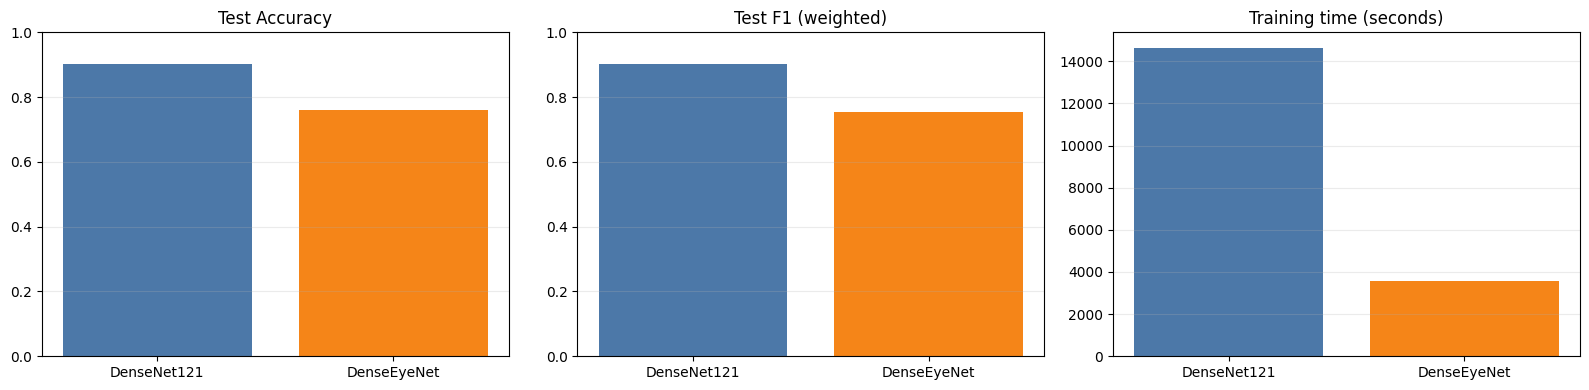

,Model,Accuracy,F1,Training Time (s)
0,DenseNet121,0.901929,0.901532,14639.402204
1,DenseEyeNet,0.761592,0.755255,3585.690817


In [55]:
# 19) Comparison graphs (DenseNet121 vs DenseEyeNet)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "results_df" not in globals() or results_df.empty:
    raise RuntimeError("results_df not found. Run the baseline + DenseEyeNet training cells first.")

needed = {"DenseNet121", "DenseEyeNet"}
present = set(results_df["Model"].astype(str).tolist())
missing = needed - present
if missing:
    raise RuntimeError(f"Missing model(s) in results_df: {sorted(missing)}. Make sure you trained both.")

cmp = (
    results_df[results_df["Model"].isin(["DenseNet121", "DenseEyeNet"])][
        ["Model", "Accuracy", "F1", "Training Time (s)"]
    ]
    .set_index("Model")
    .loc[["DenseNet121", "DenseEyeNet"]]
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Accuracy
axes[0].bar(cmp.index, cmp["Accuracy"].values, color=["#4C78A8", "#F58518"])
axes[0].set_title("Test Accuracy")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.25)

# F1
axes[1].bar(cmp.index, cmp["F1"].values, color=["#4C78A8", "#F58518"])
axes[1].set_title("Test F1 (weighted)")
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.25)

# Training time
axes[2].bar(cmp.index, cmp["Training Time (s)"].values, color=["#4C78A8", "#F58518"])
axes[2].set_title("Training time (seconds)")
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

display(cmp.reset_index())
